In [1]:
import pandas as pd
import numpy as np
from keras.models import Sequential
from keras.layers import LSTM, Input, Dropout
from keras.layers import Dense
from keras.layers import RepeatVector
from keras.layers import TimeDistributed
from matplotlib import pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from keras.models import Model
import seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view
import json
from sklearn.metrics import precision_score, f1_score, recall_score, accuracy_score, roc_auc_score

#GLOBAL VARIABLES
WINDOW_SIZE = 45

np.random.seed(77)

In [2]:
def create_lstm_windows(data, window_size):

    windows = sliding_window_view(data, window_shape=window_size, axis=0)
    X = np.swapaxes(windows, 1, 2)

    return X

In [3]:
# Load Data
raw_train_data = np.load('/content/P-4_train.npy')
raw_test_data = np.load('/content/P-4_test.npy')

#raw_train_data = np.load('/content/E-13_train.npy')
#raw_test_data = np.load('/content/E-13_test.npy') #Contextual Anomalies

#raw_train_data = np.load('/content/C-1_train.npy')
#raw_test_data = np.load('/content/C-1_test.npy') #Point and Contextual Anomalies

#  Scale data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train = scaler.fit_transform(raw_train_data)
scaled_test = scaler.transform(raw_test_data) # Uses training limits

#  Create the windows
X_train = create_lstm_windows(scaled_train, window_size=WINDOW_SIZE)
X_test = create_lstm_windows(scaled_test, window_size=WINDOW_SIZE)

print("LSTM Input Shape (X_train):", X_train.shape)


LSTM Input Shape (X_train): (2565, 45, 25)


In [4]:
#MODEL 1 DEFINITION
lstm_model1 = Sequential()
lstm_model1.add(LSTM(6, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True))
lstm_model1.add(LSTM(2, activation='relu', return_sequences=False))

lstm_model1.add(RepeatVector(X_train.shape[1]))

lstm_model1.add(LSTM(2, activation='relu', return_sequences=True))
lstm_model1.add(Dropout(0.2))
lstm_model1.add(LSTM(6, activation='relu', return_sequences=True))
lstm_model1.add(TimeDistributed(Dense(X_train.shape[2])))


lstm_model1.compile(optimizer='adam', loss='mse')
lstm_model1.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 45, 6)          │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 2)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 45, 2)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 45, 2)          │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 45, 2)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 45, 6)          │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 45, 25)         │           175 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,271 (4.96 KB)

 Trainable params: 1,271 (4.96 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
#MODEL 2 DEFINITION
lstm_model2 = Sequential()
lstm_model2.add(LSTM(4,activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False))
lstm_model2.add(Dropout(0.2))

lstm_model2.add(RepeatVector(X_train.shape[1]))

lstm_model2.add(LSTM(4, activation='relu', return_sequences=True))
lstm_model2.add(TimeDistributed(Dense(X_train.shape[2])))

lstm_model2.compile(optimizer='adam', loss='mse')
lstm_model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 4)              │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 45, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 45, 4)          │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 45, 25)         │           125 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 749 (2.93 KB)

 Trainable params: 749 (2.93 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 20s 135ms/step - loss: 0.0226 - val_loss: 0.0230
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0218 - val_loss: 0.0223
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - loss: 0.0212 - val_loss: 0.0218
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - loss: 0.0207 - val_loss: 0.0215
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - loss: 0.0204 - val_loss: 0.0212
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - loss: 0.0201 - val_loss: 0.0209
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - loss: 0.0199 - val_loss: 0.0207
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0198 - val_loss: 0.0206
Epoch 9/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - loss: 0.0196 - val_loss: 0.0205
Epoch 10/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - loss: 0.0195 - val_loss: 0.0204
Epoch 11/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - loss: 0.0194 - val_loss: 0.0203
Epoch 12/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - loss: 

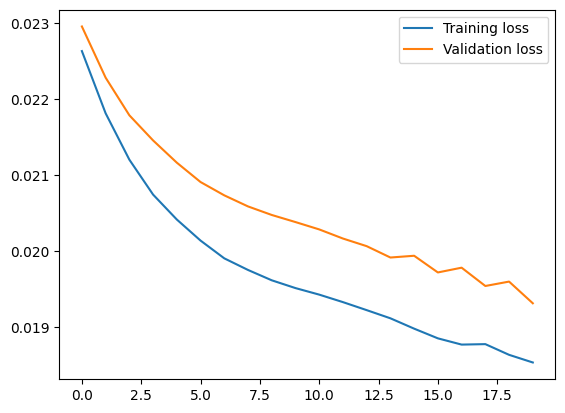

In [6]:
# FIT LSTM_MODEL 1
model_1_history = lstm_model1.fit(X_train, X_train, epochs=20, batch_size=128, validation_split=0.1, verbose=1)
plt.plot(model_1_history.history['loss'], label='Training loss')
plt.plot(model_1_history.history['val_loss'], label='Validation loss')
plt.legend()

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - loss: 0.0227 - val_loss: 0.0230
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0219 - val_loss: 0.0224
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0214 - val_loss: 0.0220
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0210 - val_loss: 0.0217
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0208 - val_loss: 0.0216
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0207 - val_loss: 0.0215
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0206 - val_loss: 0.0215
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0205 - val_loss: 0.0214
Epoch 9/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - loss: 0.0205 - val_loss: 0.0214
Epoch 10/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 0.0205 - val_loss: 0.0214
Epoch 11/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0204 - val_loss: 0.0213
Epoch 12/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0

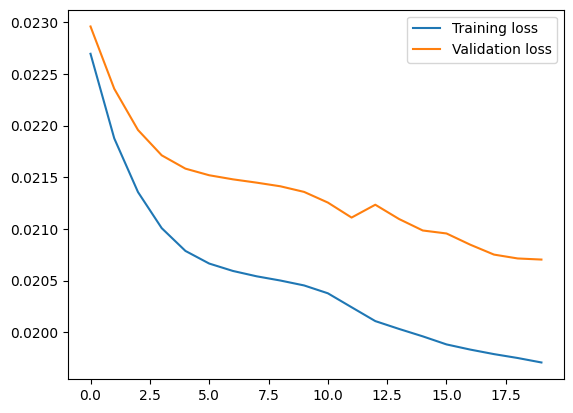

In [7]:
# FIT LSTM_MODEL 2
model_2_history = lstm_model2.fit(X_train, X_train, epochs=20, batch_size=128, validation_split=0.1, verbose=1)
plt.plot(model_2_history.history['loss'], label='Training loss')
plt.plot(model_2_history.history['val_loss'], label='Validation loss')
plt.legend()

# **Model Evaluation**

First, we label the sequence of anomalies as described by NASA in the dataset

In [8]:
y_true = np.zeros(len(X_test))  # start with all normal

# Load NASA's anomaly file
anomaly_df = pd.read_csv('labeled_anomalies.csv')
row = anomaly_df[anomaly_df['chan_id'] == 'P-4']
anomaly_sequences = json.loads(row['anomaly_sequences'].values[0])
print(anomaly_sequences)

for start, end in anomaly_sequences:
    # offset by window size since windowing shifts indices
    y_true[start:end] = 1

[[950, 1080], [2150, 2350], [4770, 4880]]


#**EVALUATING LSTM MODEL 1 - alpha model**

81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step


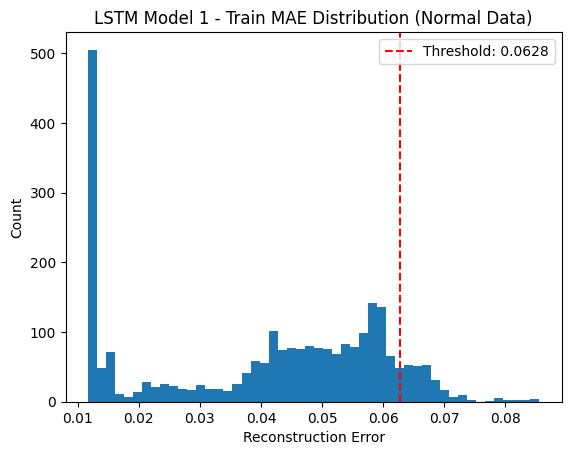

In [9]:
#SETTING THE THRESHOLD OF NORMAL BEHAVIOUR FROM TRAINING DATA
alpha_trainPredict = lstm_model1.predict(X_train)
alpha_trainMAE = np.mean(np.abs(X_train - alpha_trainPredict), axis=(1,2))

#Defining the threshold for this model
alpha_threshold = np.percentile(alpha_trainMAE, 90)

#Visualization
plt.hist(alpha_trainMAE, bins=50)
plt.title('LSTM Model 1 - Train MAE Distribution (Normal Data)')
plt.xlabel('Reconstruction Error')
plt.ylabel('Count')
plt.axvline(alpha_threshold, color='r', linestyle='--', label=f'Threshold: {alpha_threshold:.4f}')
#plt.axvline(800, color='b', linestyle='-', label=f'Stable regions')
plt.legend()
plt.show()

242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step


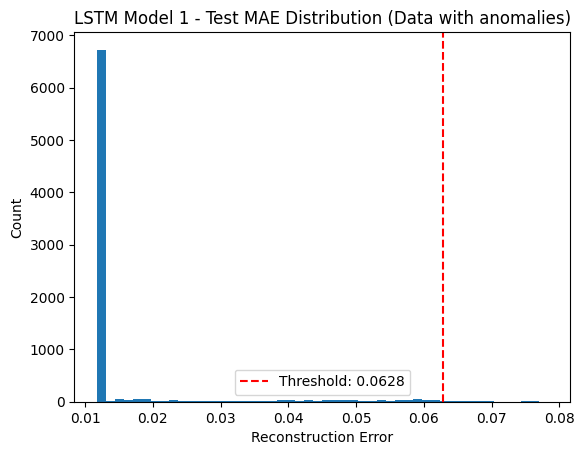

In [10]:
#FLAGGING THE ANOMALIES IN TEST DATA
alpha_testPredict = lstm_model1.predict(X_test)
alpha_testMAE = np.mean(np.abs(X_test - alpha_testPredict), axis=(1,2))

#Visualization
plt.hist(alpha_testMAE, bins=50)
plt.title('LSTM Model 1 - Test MAE Distribution (Data with anomalies)')
plt.xlabel('Reconstruction Error')
plt.ylabel('Count')
plt.axvline(alpha_threshold, color='r', linestyle='--', label=f'Threshold: {alpha_threshold:.4f}')
plt.legend()
plt.show()

# Flag anomalies
alpha_y_pred = (alpha_testMAE > alpha_threshold).astype(int)  # 1 = anomaly, 0 = normal

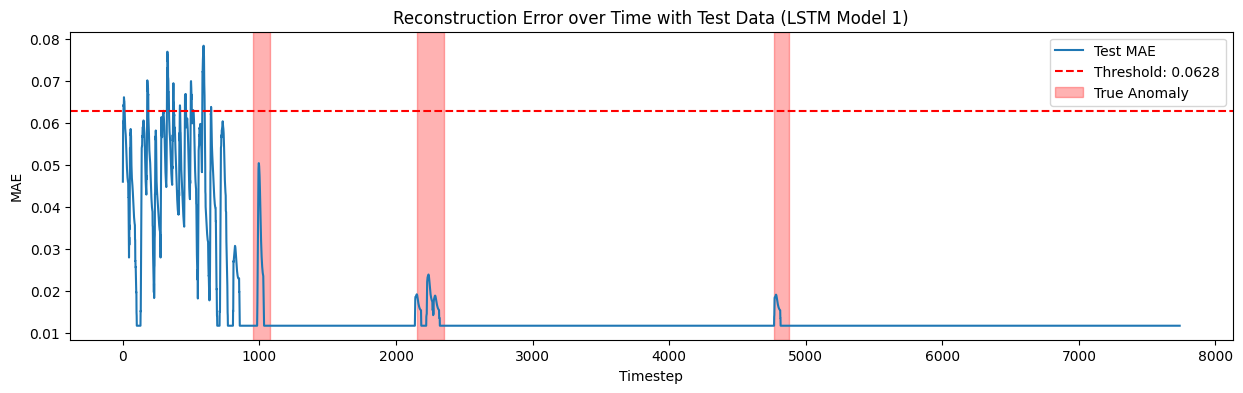

In [11]:
#RECONSTRUCTION ERROR OVER ACTUAL ANOMALIES - MODEL 1
plt.figure(figsize=(15,4))
plt.plot(alpha_testMAE, label='Test MAE')
plt.axhline(alpha_threshold, color='r', linestyle='--', label=f'Threshold: {alpha_threshold:.4f}')

# Shade stable region
#plt.axvspan(1000, len(alpha_testMAE), alpha=0.1, color='green', label='Stable Region')

# Shade anomaly regions
for i, (start, end) in enumerate(anomaly_sequences):
    plt.axvspan(start, end, alpha=0.3, color='red',
                label='True Anomaly' if i==0 else '')

plt.title('Reconstruction Error over Time with Test Data (LSTM Model 1)')
plt.xlabel('Timestep')
plt.ylabel('MAE')
plt.legend()
plt.show()

In [12]:
# Model Evaluation
print(f"LSTM Model 1 F1_Score:  {f1_score(y_true, alpha_y_pred):.6f}")
print(f"LSTM Model 1 Precision: {precision_score(y_true, alpha_y_pred):.6f}")
print(f"LSTM Model 1 Recall:    {recall_score(y_true, alpha_y_pred):.6f}")
print(f"LSTM Model 1 AUC-ROC:   {roc_auc_score(y_true, alpha_testMAE):.6f}")

LSTM Model 1 F1_Score:  0.000000
LSTM Model 1 Precision: 0.000000
LSTM Model 1 Recall:    0.000000
LSTM Model 1 AUC-ROC:   0.685067


In [13]:
print(f"Normal region MAE mean:  {alpha_testMAE[y_true==0].mean():.6f}")
print(f"Anomaly region MAE mean: {alpha_testMAE[y_true==1].mean():.6f}")

Normal region MAE mean:  0.015481
Anomaly region MAE mean: 0.016606


#**EVALUATING LSTM MODEL 2 - Beta model**

81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step


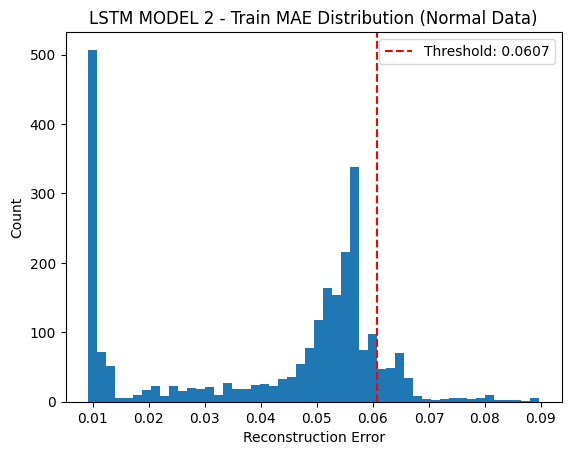

In [14]:
#SETTING THE THRESHOLD OF NORMAL BEHAVIOUR FROM TRAINING DATA

beta_trainPredict = lstm_model2.predict(X_train)
beta_trainMAE = np.mean(np.abs(X_train - beta_trainPredict), axis=(1,2))

# Threshold at 95th percentile of normal reconstruction error
beta_threshold = np.percentile(beta_trainMAE, 90)

#Visualization
plt.hist(beta_trainMAE, bins=50)
plt.title('LSTM MODEL 2 - Train MAE Distribution (Normal Data)')
plt.xlabel('Reconstruction Error')
plt.ylabel('Count')
plt.axvline(beta_threshold, color='r', linestyle='--', label=f'Threshold: {beta_threshold:.4f}')
plt.legend()
plt.show()

242/242 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step


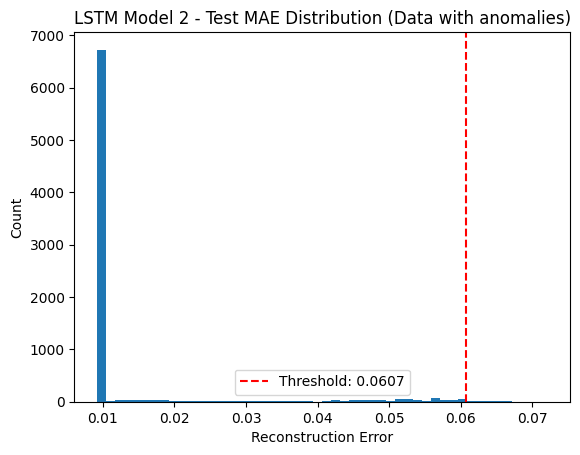

In [15]:
#FLAGGING THE ANOMALIES IN TEST DATA

beta_testPredict = lstm_model2.predict(X_test)
beta_testMAE = np.mean(np.abs(X_test - beta_testPredict), axis=(1,2))

#Visualization
plt.hist(beta_testMAE, bins=50)
plt.title('LSTM Model 2 - Test MAE Distribution (Data with anomalies)')
plt.xlabel('Reconstruction Error')
plt.ylabel('Count')
plt.axvline(beta_threshold, color='r', linestyle='--', label=f'Threshold: {beta_threshold:.4f}')
plt.legend()
plt.show()

# Flag anomalies
beta_y_pred = (beta_testMAE > beta_threshold).astype(int)  # 1 = anomaly, 0 = normal

In [16]:
#Evaluation Scores
print("M2 F1_Score: ",  f1_score(y_true, beta_y_pred))
print("M2 Precision:", precision_score(y_true, beta_y_pred))
print("M2 Recall:",    recall_score(y_true, beta_y_pred))
print("M2 AUC-ROC:",   roc_auc_score(y_true, beta_testMAE))

M2 F1_Score:  0.0
M2 Precision: 0.0
M2 Recall: 0.0
M2 AUC-ROC: 0.6826325835419548


In [17]:
print(f"Normal region MAE mean:  {beta_testMAE[y_true==0].mean():.6f}")
print(f"Anomaly region MAE mean: {beta_testMAE[y_true==1].mean():.6f}")

Normal region MAE mean:  0.013287
Anomaly region MAE mean: 0.014056


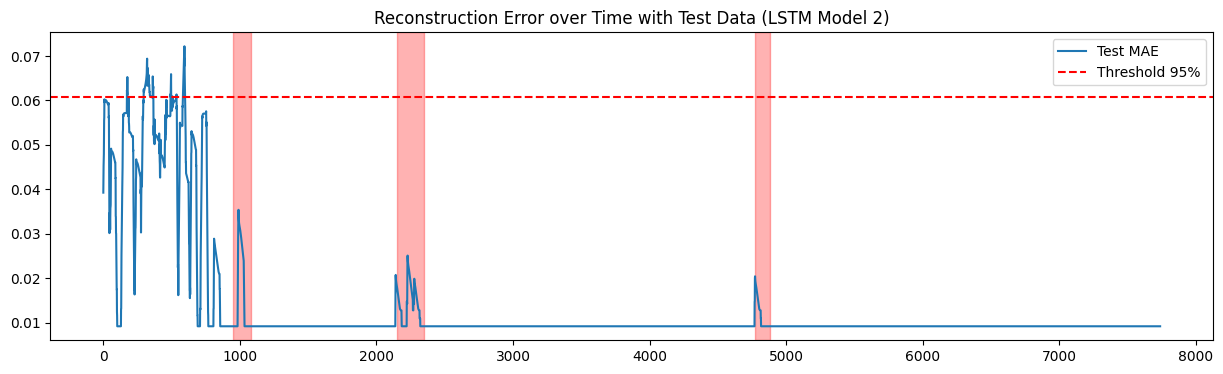

In [18]:
#RECONSTRUCTION ERROR OVER ACTUAL ANOMALIES - MODEL 2
plt.figure(figsize=(15,4))
plt.plot(beta_testMAE, label='Test MAE')
plt.axhline(beta_threshold, color='r', linestyle='--', label='Threshold 95%')
plt.title('Reconstruction Error over Time with Test Data (LSTM Model 2)')

for start, end in anomaly_sequences:
    plt.axvspan(start, end, alpha=0.3, color='red')

plt.legend()
plt.show()

## Tackling the zero-score evaluations - Model 2
Similar to the previous model above, I'll be taking the 95th percentile after the 900th time stamp to get scores on those evaluations

# UNSUPERVISED LEARNING MODEL - One Class LSTM

In [19]:
#First we prepare the data for the model by creating features for the temporal data

def extract_features(X_windows):
    # X_windows shape: (samples, timesteps, features)
    features = np.concatenate([
        np.mean(X_windows, axis=1),    # mean of each feature
        np.std(X_windows, axis=1),     # std of each feature
        np.max(X_windows, axis=1),     # max of each feature
        np.min(X_windows, axis=1),     # min of each feature
    ], axis=1)
    return features  # shape: (samples, 4*n_features)

X_train_feat = extract_features(X_train)
X_test_feat  = extract_features(X_test)

In [20]:
from sklearn.svm import OneClassSVM

ocsvm = OneClassSVM(kernel='rbf', nu=0.05)
ocsvm.fit(X_train_feat)

# Predict: returns 1 (normal) or -1 (anomaly)
raw_pred = ocsvm.predict(X_test_feat)
y_pred_svm = np.where(raw_pred == -1, 1, 0)  # convert to 1=anomaly, 0=normal

# Raw continuous scores for AUC-ROC
svm_scores = ocsvm.decision_function(X_test_feat)

In [21]:
print(f"One Class SVM")
print(f"  F1_Score:  {f1_score(y_true, y_pred_svm):.4f}")
print(f"  Precision: {precision_score(y_true, y_pred_svm):.4f}")
print(f"  Recall:    {recall_score(y_true, y_pred_svm):.4f}")
print(f"  ROC/AUC:   {roc_auc_score(y_true, -svm_scores):.6f}")

One Class SVM
  F1_Score:  0.6259
  Precision: 0.7797
  Recall:    0.5227
  ROC/AUC:   0.782453


In [22]:
print("\n===== ANOMALY DETECTION RESULTS SUMMARY - NASA P-4 =====\n")

# LSTM Model 1
model1_results = {
    "Metric": ["F1 Score", "Precision", "Recall", "AUC-ROC"],
    "Score": [
        f"{f1_score(y_true, alpha_y_pred):.4f}",
        f"{precision_score(y_true, alpha_y_pred):.4f}",
        f"{recall_score(y_true, alpha_y_pred):.4f}",
        f"{roc_auc_score(y_true, alpha_testMAE):.4f}",
    ]
}
print("LSTM Model 1 (Alpha)")
print(pd.DataFrame(model1_results).to_string(index=False))

print()

# LSTM Model 2
model2_results = {
    "Metric": ["F1 Score", "Precision", "Recall", "AUC-ROC"],
    "Score": [
        f"{f1_score(y_true, beta_y_pred):.4f}",
        f"{precision_score(y_true, beta_y_pred):.4f}",
        f"{recall_score(y_true, beta_y_pred):.4f}",
        f"{roc_auc_score(y_true, beta_testMAE):.4f}",
    ]
}
print("LSTM Model 2 (Beta)")
print(pd.DataFrame(model2_results).to_string(index=False))

print()

# One-Class SVM
svm_results = {
    "Metric": ["F1 Score", "Precision", "Recall", "AUC-ROC"],
    "Score": [
        f"{f1_score(y_true, y_pred_svm):.4f}",
        f"{precision_score(y_true, y_pred_svm):.4f}",
        f"{recall_score(y_true, y_pred_svm):.4f}",
        f"{roc_auc_score(y_true, -svm_scores):.4f}",
    ]
}
print("One-Class SVM")
print(pd.DataFrame(svm_results).to_string(index=False))


===== ANOMALY DETECTION RESULTS SUMMARY - NASA P-4 =====

LSTM Model 1 (Alpha)
   Metric  Score
 F1 Score 0.0000
Precision 0.0000
   Recall 0.0000
  AUC-ROC 0.6851

LSTM Model 2 (Beta)
   Metric  Score
 F1 Score 0.0000
Precision 0.0000
   Recall 0.0000
  AUC-ROC 0.6826

One-Class SVM
   Metric  Score
 F1 Score 0.6259
Precision 0.7797
   Recall 0.5227
  AUC-ROC 0.7825
